# Quickstart 2: a binary, the backprojected seed and the joint fit

**A star has one companion that moves. [Notebook 1](1_sinogram_fit.ipynb) fitted a sinusoid to the detections,
and assumed that every detection belongs to the companion. This notebook removes that assumption, and then
makes the measurement:**

1. **pool**: the triangulation map finds where the lines cross, and a circle about its peak selects the lines;
2. **refine**: the sinogram fit, with motion, decides which detections belong, and gives a starting point;
3. **fit**: the joint fit of all windows, from that starting point, is the measurement.

The result of steps 1 and 2 is the **seed**: the starting point of the joint fit, made from the backprojected
detections. The scene is the moving companion of notebook 1, block 11, with the same noise. The paper's own
example of these steps is Figure 3 (Sect. 4.5; [`paper/fig3_moving_companion.ipynb`](../paper/fig3_moving_companion.ipynb)).

| block | task | call | paper |
|---|---|---|---|
| 1 | the data: windows and detections | `sim.simulate_campaign`, `red.reduce_campaign` | Sect. 2, Eq. 8 |
| 2 | the lines on the sky, and their map | `red.ladder_window`, `bp.backprojection_map` | Sect. 3.1, Eq. 10; Sect. 3.3, Eq. 13, Fig. 2c |
| 3 | pool: the peak | `bp.map_peak` | Sect. 3.3 |
| 4 | pool: the lines near the peak | `bp.peak_consistency` | Sect. 4.2 |
| 5 | refine: the robust sinogram fit to the pool | `dyn.fit_motion_robust` | Sect. 4.2, Eq. 15 |
| 6 | refine: test every detection against the track, fit again | `dyn.motion_design`, `dyn.fit_motion` | Sect. 4.2 |
| 7 | pool and refine in one call: the seed | `dyn.clean_detection_set` | Sect. 4.2 |
| 8 | the map as measured and refocused | `dyn.to_reference_epoch`, `bp.backprojection_map` | Eq. 17, Fig. 3 |
| 9 | fit: the joint fit of all windows | `joint.fit_joint` | Sect. 4.3, Eq. 18 |
| 10 | what the joint fit computes | `joint.loglike_profiled`, `joint.joint_fisher`, `joint.joint_covariance` | Eq. 18, App. B |
| 11 | the result, and the truth | `joint.polar_elements` | Sect. 4.5 |
| 12 | options: parallax, a free primary | `joint.fit_joint` | Eq. 16, Sect. 4.5 |

**The series.** [1](1_sinogram_fit.ipynb): the sinogram fit. 2 (this notebook). [3](3_triple_ladder.ipynb):
three sources, the search.

**Conventions** ([`docs/conventions.md`](../../docs/conventions.md)): as in notebook 1. A parameter vector of
a moving source is (Δα\*, Δδ, μα\*, μδ) in mas and mas/yr. Maps are drawn with east to the left.

In [1]:
# the imports: numpy, matplotlib, and the scanlib modules; every scanlib call below carries its module's name
import numpy as np
import matplotlib.pyplot as plt

from scanlib import instrument as ins      # the instrument: sampling, LSF, the along-scan projection (Eq. 9)
from scanlib import noise                  # the noise model of a window
from scanlib import scanlaw                # scan angles, epochs and parallax factors
from scanlib import simulation as sim      # synthetic scenes and their windows
from scanlib import reduction as red       # one window, or a campaign, reduced to detections
from scanlib import backprojection as bp   # the triangulation map and its peak
from scanlib import dynamics as dyn        # the fits to the detections (the sinogram fits)
from scanlib import joint                  # the joint fit of all windows, and its helpers

In [2]:
# the plot style of the paper's figures, and the axis labels of a sky map
plt.rcParams.update({"font.size": 10.0, "axes.linewidth": 0.5, "xtick.labelsize": 9.0, "ytick.labelsize": 9.0,
                     "xtick.direction": "in", "ytick.direction": "in", "legend.frameon": False, "legend.fontsize": 8.0})
ACCENT, ACCENT_2 = "tomato", "dodgerblue"
EAST, NORTH = r"$\Delta\alpha^{*}$  [mas]   (East $\leftarrow$)", r"$\Delta\delta$  [mas]"

In [3]:
# a helper for the plots: the two ends of a detection's line on the sky
def sky_line(psi_i, eta_i, half=450.0):
    """The ends (dra*, ddec) of the line dra* sin(psi) + ddec cos(psi) = eta (Eq. 10), `half` mas each way.

    Inputs
        psi_i   the scan angle of the detection [rad]
        eta_i   its position along the scan [mas]
        half    half the length of the line that is drawn [mas]
    Returns an array of shape (2, 2): row 0 holds the dra* of the two ends, row 1 their ddec [mas]"""
    foot = eta_i * np.array([np.sin(psi_i), np.cos(psi_i)])        # the point of the line nearest the origin
    along = np.array([np.cos(psi_i), -np.sin(psi_i)])              # the direction of the line
    return np.array([foot - half * along, foot + half * along]).T  # .T: row 0 is dra*, row 1 is ddec

## 1. The data

*Paper: Sect. 2 (the windows), Eq. 8 (the detections).* The blocks 1 to 5 of notebook 1, in three cells, with
the same instrument, scan law and noise (a G = 16 primary).

In [4]:
# the instrument and the scan law (notebook 1, blocks 1 and 2)
inst = ins.Instrument.gaussian(fwhm_mas=100.0, pitch_mas=59.0, n_samples=18, margins=ins.TOY_MARGINS)
psi, tau = scanlaw.load_scan_law(scanlaw.PLEIADES)

print(f"{psi.size} transits over {tau.max() - tau.min():.1f} yr")

47 transits over 5.1 yr


In [5]:
# the truth: a companion 200 mas from the primary, 0.2 of its flux, moving (3, 9) mas/yr; np.r_ joins its
# position and its motion into one vector (dra*, ddec, mu_a*, mu_d)
SEED = 7                                         # the seed of the noise draw
PM = (3.0, 9.0)                                  # the proper motion (mu_a*, mu_d) [mas/yr]
scene = sim.Scene.pair(200.0, 110.0, 0.2, pm=PM)
TRUTH = np.r_[scene.positions[1], PM]            # row 1 of the positions is the companion; row 0 is the primary

path_mas = np.hypot(*PM) * (tau.max() - tau.min())                 # np.hypot(*PM): the size of the motion [mas/yr]
print("truth (dra*, ddec, mu_a*, mu_d):", TRUTH.round(2).tolist(),
      f"; the companion moves {path_mas:.0f} mas over the campaign")

truth (dra*, ddec, mu_a*, mu_d): [187.94, -68.4, 3.0, 9.0] ; the companion moves 48 mas over the campaign


In [6]:
# the noise model, the zero point of each window, and the 47 windows with the sigma of every sample
# noise.gaia_like: the noise of a G = 16 primary whose total flux is sim.PRIMARY_FLUX, in the windows' flux units
# (notebook 1, block 3, explains the units)
noise_model = noise.gaia_like(16.0, sim.PRIMARY_FLUX)
# rng_zero_points: the zero points' own stream; its seed is [the noise seed, the label 1 of this stream].
# rng_noise: the generator of the windows' noise; its seed is SEED alone
rng_zero_points = np.random.default_rng([SEED, 1])
eta0 = sim.random_zero_points(rng_zero_points, psi.size, inst)
rng_noise = np.random.default_rng(SEED)
# sim.simulate_campaign also returns the sources' true positions along the scan (dropped here, the name _)
windows, sigma, _ = sim.simulate_campaign(scene, (psi, tau), rng_noise, inst, noise_model, eta0=eta0)
windows = np.asarray(windows)                    # one array (transits, samples) in place of a list of windows
sigma = np.asarray(sigma)

print(f"windows {windows.shape}, sigma {sigma.shape} [flux per sample]")

windows (47, 18), sigma (47, 18) [flux per sample]


In [7]:
# the detections: every window reduced alone (notebook 1, blocks 4 and 5)
det = red.reduce_campaign((psi, tau), windows, inst, sigma, k_max=2, eta0=eta0)

print(f"{det.eta.size} detections; {det.n_censored_windows} of {det.n_windows} windows gave none")
print(f"errors sigma from {det.sigma.min():.2f} to {det.sigma.max():.2f} mas, median {np.median(det.sigma):.2f}")

44 detections; 3 of 47 windows gave none
errors sigma from 0.19 to 9.12 mas, median 0.23


## 2. The lines on the sky, and their map

*Paper: Sect. 3.1, Eq. 10 (a line); Sect. 3.3, Eq. 13, Fig. 2c (the map).* A position η along a scan of angle
ψ does not give a point on the sky. It gives a **line**: all the positions with

$$\Delta\alpha^{*}\sin\psi + \Delta\delta\cos\psi = \eta .$$

Each window gives one line for each source that it resolves. The lines of one source cross at its position.
The detections (block 1) are the lines of the companion. To draw the primary's lines also, the next cell
takes the primary's position from each window.

In [8]:
# the primary's position along the scan in each window, and its error: of the sources that red.ladder_window
# finds, the one that red.delivery_mask does NOT deliver (~ inverts the mask; a window of one source holds the
# primary alone); + eta0[j] moves the position from the window's frame to the sky
eta_primary = np.empty(psi.size)                 # the primary's position on the sky [mas], one per window
sigma_primary = np.empty(psi.size)               # its error [mas]
for j in range(psi.size):                        # j counts the windows
    # the sources of window j; the number of sources and the record of the fits are dropped (the two _)
    eta_j, flux_j, _, _ = red.ladder_window(windows[j], inst, sigma[j], k_max=2)
    if eta_j.size > 1:
        is_primary = ~red.delivery_mask(eta_j, origin=-eta0[j])
    else:
        is_primary = np.array([True])
    err_j = red.sigma_eta(eta_j, flux_j, inst, sigma[j])
    eta_primary[j] = eta_j[is_primary][0] + eta0[j]                # [is_primary][0]: the first source of the mask
    sigma_primary[j] = err_j[is_primary][0]

print(f"the primary: {eta_primary.size} positions, from {eta_primary.min():+.2f} to {eta_primary.max():+.2f} mas, "
      f"median error {np.median(sigma_primary):.2f} mas")

the primary: 47 positions, from -0.67 to +3.87 mas, median error 0.08 mas


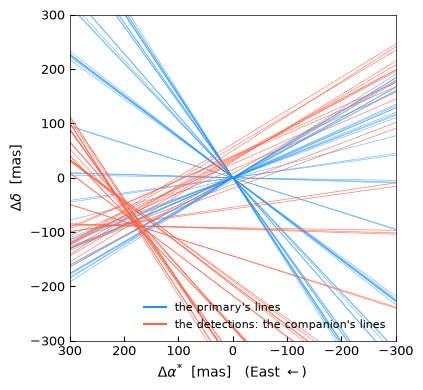

In [9]:
# the lines on the sky: the primary's (blue) cross at the origin; the companion's (red) cross near one place
fig, ax = plt.subplots(figsize=(4.2, 4.0))
# *sky_line(...): the two rows that sky_line returns, the ends' dra* and ddec, are the x and y of the plotted line
for psi_line, eta_line in zip(psi, eta_primary):
    ax.plot(*sky_line(psi_line, eta_line), "-", color=ACCENT_2, lw=0.5, alpha=0.6)
for psi_line, eta_line in zip(det.psi, det.eta):
    ax.plot(*sky_line(psi_line, eta_line), "-", color=ACCENT, lw=0.5, alpha=0.8)
# two empty lines, for the legend only
ax.plot([], [], "-", color=ACCENT_2, label="the primary's lines")
ax.plot([], [], "-", color=ACCENT, label="the detections: the companion's lines")
ax.set(xlim=(300, -300), ylim=(-300, 300), xlabel=EAST, ylabel=NORTH, aspect="equal")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

The primary's lines cross at one point, the origin: the primary defines the reference position, and it is
not searched for. The companion's lines do not cross at one point, because the companion moves between the
scans.

`bp.backprojection_map` adds the detections' lines on a sky grid (Eq. 13). Each line is a ridge with the
width of its error σ, so a place where many lines cross is a peak.

In [10]:
# the map of the detections: each line as a ridge, summed on a grid of 0.5 mas pixels over +-350 mas
sky, axis, extent = bp.backprojection_map(det.psi, det.eta, det.sigma, half_size=350.0, step=0.5)

print(f"map {sky.shape} [1/mas]; rows are ddec, columns dra*; axis from {axis[0]:.0f} to {axis[-1]:.0f} mas")

map (1401, 1401) [1/mas]; rows are ddec, columns dra*; axis from -350 to 350 mas


## 3. Pool: the peak of the map

*Paper: Sect. 3.3.* `bp.map_peak` returns the highest peak of the map outside 30 mas of the primary
(`origin_zone`), and the width of the map at that peak. The peak says roughly where the companion is. It is
not a measurement.

In [11]:
# the highest peak of the map, and the map's width there
# bp.map_peak also returns its map and the map's axis (dropped here, the two _)
peak, width, _, _ = bp.map_peak(det.psi, det.eta, det.sigma, half_size=300.0, step=1.0, origin_zone=30.0)

print(f"peak at ({peak[0]:+.0f}, {peak[1]:+.0f}) mas, width {width:.1f} mas")
# truth: the distance of the peak from the true position; [0] is dra*, [1] is ddec
peak_error = np.hypot(peak[0] - TRUTH[0], peak[1] - TRUTH[1])
print(f"truth at the reference epoch: ({TRUTH[0]:+.1f}, {TRUTH[1]:+.1f}) mas: the peak is "
      f"{peak_error:.0f} mas from it")

peak at (+216, -29) mas, width 0.5 mas
truth at the reference epoch: (+187.9, -68.4) mas: the peak is 48 mas from it


The peak is far from the companion's position at the reference epoch. A moving source has no single crossing:
the peak is where the lines of some epochs happen to cross.

## 4. Pool: the lines near the peak

*Paper: Sect. 4.2.* `bp.peak_consistency` returns two arrays. The second is the distance of the peak from
each detection's line, in mas. The pool is the detections whose line passes within 30 mas of the peak. The
circle is wide on purpose: the lines of a moving source do not cross at one point.

The radius is an option, not a fixed part of the method. `dyn.SELECT_RADIUS_MAS` is only its default value,
30 mas; in `dyn.clean_detection_set` (block 7) it is the argument `select_radius`. Make it larger for a
faster source, and smaller when a second source is near. On this scene the seed is the same for every radius
from 5 to 100 mas, because block 6 tests all the detections again.

In [12]:
# the distance of each line from the peak; [1] takes the second return, the distances (the first is a 3-sigma
# test, used for a source at rest)
distance = bp.peak_consistency(det.psi, det.eta, det.sigma, peak, width)[1]
pool = distance <= dyn.SELECT_RADIUS_MAS                      # a mask: True for the detections in the pool

# ~pool inverts the mask: the detections that are not in the pool

print(f"{pool.sum()} of {pool.size} detections are in the pool (within {dyn.SELECT_RADIUS_MAS:.0f} mas of the peak)")
print(f"the others pass {distance[~pool].min():.0f} to {distance[~pool].max():.0f} mas from the peak")

24 of 44 detections are in the pool (within 30 mas of the peak)
the others pass 34 to 76 mas from the peak


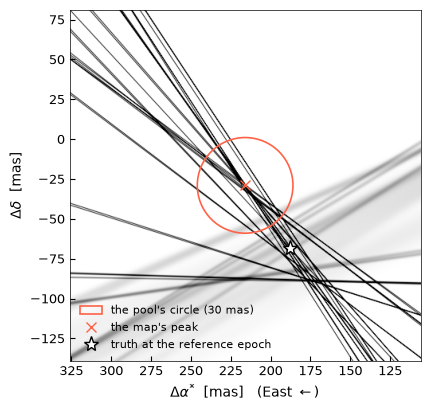

In [13]:
# the map about the peak, with the circle of the pool. Each detection is a ridge as wide as its error: most are
# a fraction of a mas wide, a few are several mas wide
fig, ax = plt.subplots(figsize=(4.4, 4.2))
ax.imshow(sky, origin="lower", extent=extent, cmap="gray_r", vmax=0.25 * sky.max())
circle = plt.Circle(peak, dyn.SELECT_RADIUS_MAS, fill=False, ec=ACCENT, lw=1.2, label="the pool's circle (30 mas)")
ax.add_patch(circle)
ax.plot(*peak, "x", color=ACCENT, ms=7, label="the map's peak")              # *peak: its dra* and ddec
ax.plot(TRUTH[0], TRUTH[1], "*", mfc="white", mec="k", ms=11, label="truth at the reference epoch")
# 110 mas each way about the peak; East (larger dra*) is to the left
ax.set(xlim=(peak[0] + 110, peak[0] - 110), ylim=(peak[1] - 110, peak[1] + 110), xlabel=EAST, ylabel=NORTH,
       aspect="equal")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

The lines that do not pass through the circle are also the companion's. They are outside it only because the
companion was at another place at their epochs. Block 6 returns them.

## 5. Refine: the robust sinogram fit

*Paper: Sect. 4.2, Eq. 15.* The fit of notebook 1, block 12, on the pool **only**: position and proper motion,
with Huber weights, so that a wrong line inside the circle has little effect. The detections outside the pool
are not used here.

In [14]:
# the Huber fit of position and motion to the pool; [pool] keeps the detections of the pool only
# of its four returns, the covariance and the detections at the reference epoch are dropped (the two _)
theta, _, weights, _ = dyn.fit_motion_robust(det.psi[pool], det.tau[pool], det.eta[pool], det.sigma[pool])

print("first fit (dra*, ddec, mu_a*, mu_d):", theta.round(2).tolist())
print(f"Huber weights: {np.sum(weights < 1)} of {weights.size} below 1, smallest {weights.min():.2f}")

first fit (dra*, ddec, mu_a*, mu_d): [187.9, -68.52, 3.03, 9.09]
Huber weights: 3 of 24 below 1, smallest 0.71


The same detections as a sinogram (notebook 1, block 6). The curve is the sinusoid of the fitted position at
the reference epoch. A moving source is not on one sinusoid: each detection is off the curve by the motion
times its epoch (Eq. 15).

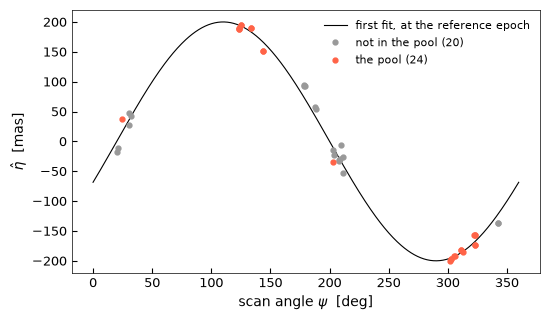

In [15]:
# the sinogram: the detections of the pool (red, used in the first fit) and the others (gray, not used), with
# the sinusoid of the first fit's position; ~pool inverts the mask
fine = np.linspace(0, 2 * np.pi, 400)            # 400 scan angles over the full turn [rad], to draw the curve
curve_fine = ins.project_al(theta[0], theta[1], fine)              # the sinusoid of the fitted (dra*, ddec) [mas]
fig, ax = plt.subplots(figsize=(5.6, 3.3))
ax.plot(np.rad2deg(fine), curve_fine, "-", color="k", lw=0.8, label="first fit, at the reference epoch")
ax.plot(np.rad2deg(det.psi[~pool]) % 360, det.eta[~pool], "o", color="0.6", ms=3.5,
        label=f"not in the pool ({np.sum(~pool)})")
ax.plot(np.rad2deg(det.psi[pool]) % 360, det.eta[pool], "o", color=ACCENT, ms=3.5,
        label=f"the pool ({pool.sum()})")
ax.set(xlabel=r"scan angle $\psi$  [deg]", ylabel=r"$\hat\eta$  [mas]")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 6. Refine: test every detection, then fit again

*Paper: Sect. 4.2.* From here the circle has no function. The first fit gives a **track**: where the
companion is at each epoch. Now **every** detection is tested against the track, also the detections outside
the pool. A detection belongs when it lies on the track at its own epoch:

$$|\hat\eta_i - \mathbf X_i\boldsymbol\theta| \le \max(3\sigma_i,\ w),$$

where **X**ᵢ is the row of `dyn.motion_design` (notebook 1, block 11), so **X**ᵢθ is the track's along-scan
position at the epoch of detection *i*, and *w* is the width of the map at the peak.

In [16]:
# the distance of every detection from the first fit's track, and the limit of the test, max(3 sigma, w)
X = dyn.motion_design(det.psi, det.tau)                       # one row per detection, four columns
off_track = det.eta - X @ theta                               # [mas]; @ is the matrix product
limit = np.maximum(3.0 * det.sigma, width)                    # [mas], one value per detection

print(f"in the pool:     |distance| up to {np.abs(off_track[pool]).max():.2f} mas")
print(f"not in the pool: |distance| up to {np.abs(off_track[~pool]).max():.2f} mas")

in the pool:     |distance| up to 1.92 mas
not in the pool: |distance| up to 5.45 mas


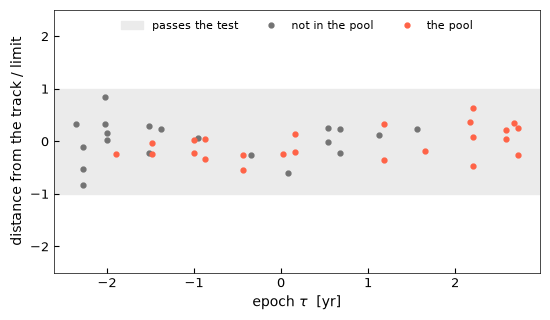

In [17]:
# the test as a picture: each detection's distance from the track in units of its own limit; inside +-1 it passes
fig, ax = plt.subplots(figsize=(5.6, 3.3))
ax.axhspan(-1.0, 1.0, color="0.92", label="passes the test")
ax.plot(det.tau[~pool], off_track[~pool] / limit[~pool], "o", color="0.45", ms=3.5, label="not in the pool")
ax.plot(det.tau[pool], off_track[pool] / limit[pool], "o", color=ACCENT, ms=3.5, label="the pool")
ax.set(xlabel=r"epoch $\tau$  [yr]", ylabel="distance from the track / limit", ylim=(-2.5, 2.5))
ax.legend(loc="upper center", ncol=3)
plt.tight_layout()
plt.show()

The detections outside the pool lie on the track also: they are the companion's lines of other epochs. They
pass the test, and so they come back. A line of another source, or a false detection, is off the track; it
fails the test and is left out. Then a least-squares fit to all the detections that pass.

In [18]:
# pass 1: the test, and the least-squares fit to the detections that pass; [keep] takes those detections only
keep = np.abs(off_track) <= limit
# the third return of dyn.fit_motion, the detections at the reference epoch, is dropped (the name _)
theta, cov, _ = dyn.fit_motion(det.psi[keep], det.tau[keep], det.eta[keep], det.sigma[keep])

n_from_outside = np.sum(keep & ~pool)            # kept and not in the pool
print(f"pass 1: {keep.sum()} of {keep.size} detections kept ({n_from_outside} of them from outside the pool)")
print("fit to the kept ones:", theta.round(2).tolist())

pass 1: 44 of 44 detections kept (20 of them from outside the pool)
fit to the kept ones: [187.99, -68.37, 2.92, 8.96]


In [19]:
# pass 2: the same test with the new fit; when the kept set does not change, the cleaning is complete
off_track_2 = det.eta - X @ theta                # [mas], the distance from the track of pass 1's fit
keep_2 = np.abs(off_track_2) <= limit            # the same limit as in pass 1, max(3 sigma, w)

print(f"pass 2: {keep_2.sum()} kept; the same set as pass 1: {np.array_equal(keep_2, keep)}")

pass 2: 44 kept; the same set as pass 1: True


## 7. Pool and refine in one call: the seed

*Paper: Sect. 4.2.* `dyn.clean_detection_set` does blocks 3 to 6. It returns the fit and its covariance, the
mask of the kept detections, and a record `info` of each step. This fit is the **seed** of the joint fit.

In [20]:
# the same steps in one call: the fit, its covariance, the kept detections, and the record
seed, seed_cov, keep_c, info = dyn.clean_detection_set(det.psi, det.tau, det.eta, det.sigma)

assert np.array_equal(seed, theta) and np.array_equal(keep_c, keep)
print(f"the same fit and the same kept set; {info['n_selected']} in the pool, {info['iterations']} passes, "
      f"settled: {info['converged']}")
NAMES = ("dra*  [mas]", "ddec  [mas]", "mu_a* [mas/yr]", "mu_d  [mas/yr]")     # the four parameters, in theta's order
seed_err = np.sqrt(np.diag(seed_cov))            # the errors: the square roots of the covariance's diagonal
for name, value, error, true_value in zip(NAMES, seed, seed_err, TRUTH):
    print(f"  {name:15s} {value:+8.2f} +- {error:.2f}   (truth {true_value:+.2f})")

the same fit and the same kept set; 24 in the pool, 2 passes, settled: True
  dra*  [mas]      +187.99 +- 0.13   (truth +187.94)
  ddec  [mas]       -68.37 +- 0.14   (truth -68.40)
  mu_a* [mas/yr]     +2.92 +- 0.08   (truth +3.00)
  mu_d  [mas/yr]     +8.96 +- 0.07   (truth +9.00)


**Options of `dyn.clean_detection_set`.**

| option | default | what it does |
|---|---|---|
| `select_radius` | 30 mas (`dyn.SELECT_RADIUS_MAS`) | the radius of the pool about the peak (block 4) |
| `huber_delta`, `huber_iter` | 1.345, 25 | the Huber fit of block 5 |
| `k_sigma` | 3 | the test of block 6, in units of each detection's σ |
| `origin_zone` | 30 mas | the peak is searched outside this radius of the primary |
| `max_iter` | 5 | the largest number of passes of block 6 |
| `fpar`, `parallax` | none, False | also fit a parallax difference (block 12) |
| `static` | False | True: a source at rest; no motion columns, the lines through the peak, one fit |

The seed is a starting point, not the measurement. It uses one number per window, it does not use the
censored windows, and a detection near the primary is pulled by the blend (Sect. 4.5). The measurement is
block 9.

## 8. The map as measured, and refocused

*Paper: Eq. 17, Fig. 3 (bottom row).* `dyn.to_reference_epoch` subtracts the fitted motion from each detection.
The map of the corrected detections is the paper's **dynamical backprojection**: the map is refocused. The
lines now cross at one point, the companion's position at the reference epoch, as the lines of a source at
rest do. The primary's map is the reference for that.

The refocused map uses **all** the detections, not only the pool: the seed is the fit to every detection that
passed the test of block 6. A detection that fails the test is moved and drawn also; its ridge misses the
crossing. Here no detection fails.

In [21]:
# the detections moved to the reference epoch with the fitted motion (Eq. 17), and the map of them
eta_ref = dyn.to_reference_epoch(seed, det.psi, det.tau, det.eta)
sky_ref, _, _ = bp.backprojection_map(det.psi, eta_ref, det.sigma, half_size=350.0, step=0.5)   # axis, extent dropped

print(f"the correction moves a detection by up to {np.abs(eta_ref - det.eta).max():.0f} mas; "
      f"the map's highest value rises from {sky.max():.1f} to {sky_ref.max():.1f} per mas")

the correction moves a detection by up to 25 mas; the map's highest value rises from 9.1 to 38.1 per mas


In [22]:
# for reference, the map of the primary's lines (block 2): a source at rest, whose lines cross at one point.
# For the picture only, np.maximum makes each ridge at least one pixel (0.5 mas) wide: the primary's errors
# (0.08 mas) are narrower than a pixel
ridge_width = np.maximum(sigma_primary, 0.5)                                   # [mas]
sky_primary, _, _ = bp.backprojection_map(psi, eta_primary, ridge_width, half_size=350.0, step=0.5)
row, column = np.unravel_index(np.argmax(sky_primary), sky_primary.shape)      # the pixel of the highest value

print(f"the primary's map: {psi.size} lines; its highest value is at ({axis[column]:+.1f}, {axis[row]:+.1f}) mas")

the primary's map: 47 lines; its highest value is at (+0.0, +0.0) mas


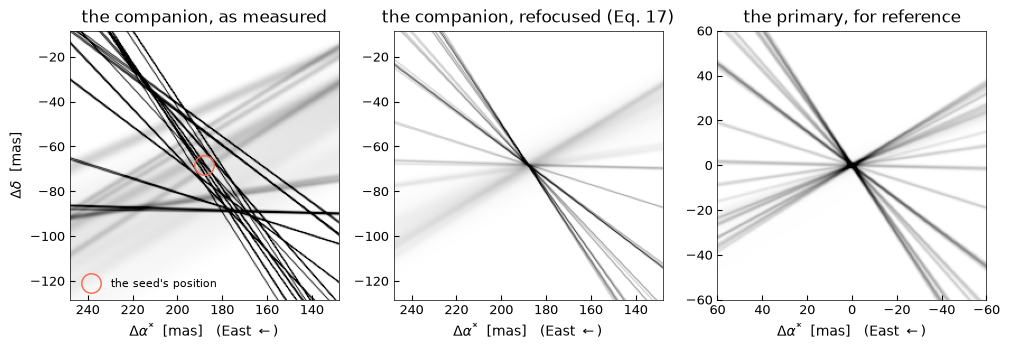

In [23]:
# three maps, each 120 mas wide: the companion as measured, the companion refocused (Eq. 17), and the primary
# each panel: (the map, the centre of the view (dra*, ddec) [mas], the title); seed[:2] is the seed's position
panels = ((sky, seed[:2], "the companion, as measured"), (sky_ref, seed[:2], "the companion, refocused (Eq. 17)"),
          (sky_primary, (0.0, 0.0), "the primary, for reference"))
fig, axes = plt.subplots(1, 3, figsize=(10.2, 3.7))
for ax, (image, centre, title) in zip(axes, panels):
    ax.imshow(image, origin="lower", extent=extent, cmap="gray_r", vmax=0.25 * image.max())
    ax.set(xlim=(centre[0] + 60, centre[0] - 60), ylim=(centre[1] - 60, centre[1] + 60), xlabel=EAST, title=title,
           aspect="equal")
axes[0].set_ylabel(NORTH)
axes[0].plot(seed[0], seed[1], "o", mfc="none", mec=ACCENT, ms=14, label="the seed's position")
axes[0].legend(loc="lower left")
plt.tight_layout()
plt.show()

## 9. Fit: the joint fit of all windows

*Paper: Sect. 4.3, Eq. 18.* The joint fit does not use the detections. It models the samples of **all 47
windows** at once, also the censored ones: two sources, each at its position at the window's epoch, through
the LSF. `joint.fit_joint` maximizes the likelihood of Eq. 18 over the companion's four parameters, from the
seed of block 7. The fluxes are solved inside.

In [24]:
# the joint fit: all windows, the companion's position and motion, started from the seed
fit = joint.fit_joint(windows, psi, seed, inst, sigma, tau=tau, eta0=eta0)

print("returned:", ", ".join(fit))                       # fit is a dictionary; these are the names of its entries
print(f"converged: {fit['converged']}; chi2 {fit['chi2']:.0f} for {np.size(windows)} samples")
for name, value, error in zip(NAMES, fit["theta"], fit["sigma_theta"]):
    print(f"  {name:15s} {value:+8.2f} +- {error:.2f}")
flux_ratio = fit["flux"][1] / fit["flux"][0]             # the companion's flux [1] over the primary's [0]
print(f"fluxes (primary, companion): {fit['flux'].round(1).tolist()}; ratio {flux_ratio:.3f}")

returned: theta, flux, cov, sigma_theta, chi2, chi2_prior, loglike, n_restarts, converged
converged: True; chi2 746 for 846 samples
  dra*  [mas]      +187.93 +- 0.07
  ddec  [mas]       -68.45 +- 0.06
  mu_a* [mas/yr]     +2.92 +- 0.04
  mu_d  [mas/yr]     +8.96 +- 0.03
fluxes (primary, companion): [999.0, 200.0]; ratio 0.200


## 10. What the joint fit computes

*Paper: Eq. 18 (the likelihood), App. B (the errors).* Three calls are inside `joint.fit_joint`:

- `joint.loglike_profiled`: ln L of Eq. 18 at given parameters, with the best fluxes. The fit maximizes it.
- `joint.joint_fisher`: the Fisher matrix of the parameters and the fluxes at the solution.
- `joint.joint_covariance`: its inverse, and the 1σ errors of the parameters.

In [25]:
# the likelihood at the seed and at the solution: the fit raised it
lnL_seed = joint.loglike_profiled(seed, windows, psi, inst, sigma, tau, eta0=eta0)
# return_fluxes=True: the call also returns the fluxes (primary, companion) that maximize the likelihood there
lnL_fit, flux = joint.loglike_profiled(fit["theta"], windows, psi, inst, sigma, tau, eta0=eta0,
                                       return_fluxes=True)

print(f"ln L at the seed {lnL_seed:.1f}, at the solution {lnL_fit:.1f}: a gain of {lnL_fit - lnL_seed:.1f}")

ln L at the seed 624.9, at the solution 625.9: a gain of 1.1


In [26]:
# the errors: the Fisher matrix of (4 parameters, 2 fluxes) at the solution, and its inverse
fisher = joint.joint_fisher(fit["theta"], flux, psi, inst, sigma, tau, eta0=eta0)
cov, sigma_theta = joint.joint_covariance(fisher, 4)          # 4: the number of parameters before the fluxes

assert np.allclose(sigma_theta, fit["sigma_theta"]) and np.allclose(cov, fit["cov"])
print("Fisher matrix", fisher.shape, "; its inverse gives the errors of block 9:", sigma_theta.round(2).tolist())

Fisher matrix (6, 6) ; its inverse gives the errors of block 9: [0.07, 0.06, 0.04, 0.03]


## 11. The result, and the truth

*Paper: Sect. 4.5.* The seed and the joint fit against the truth, each with its own error and its distance
from the truth in units of that error.

In [27]:
# truth: each fit's distance from the true value, in units of the fit's own error
print(f"{'':17s} {'the seed':>30s} {'the joint fit':>30s}")
for i, name in enumerate(NAMES):                         # i counts the four parameters
    seed_error = np.sqrt(seed_cov[i, i])                 # the seed's error of parameter i
    joint_error = fit["sigma_theta"][i]                  # the joint fit's error of parameter i
    seed_pull = (seed[i] - TRUTH[i]) / seed_error
    joint_pull = (fit["theta"][i] - TRUTH[i]) / joint_error
    print(f"  {name:15s} {seed[i]:+8.2f} +- {seed_error:.2f} ({seed_pull:+5.1f} sigma)"
          f"   {fit['theta'][i]:+8.2f} +- {joint_error:.2f} ({joint_pull:+5.1f} sigma)")

                                        the seed                  the joint fit
  dra*  [mas]      +187.99 +- 0.13 ( +0.4 sigma)    +187.93 +- 0.07 ( -0.2 sigma)
  ddec  [mas]       -68.37 +- 0.14 ( +0.3 sigma)     -68.45 +- 0.06 ( -0.7 sigma)
  mu_a* [mas/yr]     +2.92 +- 0.08 ( -1.1 sigma)      +2.92 +- 0.04 ( -1.9 sigma)
  mu_d  [mas/yr]     +8.96 +- 0.07 ( -0.6 sigma)      +8.96 +- 0.03 ( -1.2 sigma)


In [28]:
# the measurement as a separation and a position angle at the reference epoch; [:2] and [:2, :2] keep the
# position entries of the parameter vector and of its covariance
rho, rho_err, pa, pa_err = joint.polar_elements(fit["theta"][:2], fit["cov"][:2, :2])

print(f"rho = {rho:.2f} +- {rho_err:.2f} mas (truth 200), PA = {pa:.2f} +- {pa_err:.2f} deg (truth 110)")

rho = 200.00 +- 0.05 mas (truth 200), PA = 110.01 +- 0.02 deg (truth 110)


This is one noise draw, so a difference of 2σ in one parameter is not a fault. The paper compares the two
fits over 300 draws of its own scene (Sect. 4.5;
[`paper/fig3_moving_companion.ipynb`](../paper/fig3_moving_companion.ipynb), section 11): the seed is biased
by about 1 mas and 0.4 to 0.5 mas/yr, and its scatter is larger than its errors by up to 50 %; the joint fit
shows no significant bias, and its scatter agrees with its errors.

## 12. Options: a parallax difference, a free primary

*Paper: Eq. 16, Sect. 4.5.* **Parallax.** A companion at another distance has a parallax difference Δϖ. Give
the along-scan parallax factors `fpar` to both steps. Each source then has five parameters. This companion
has none, so Δϖ must agree with 0.

In [29]:
# five parameters: the scan law with its parallax factors, the detections, the seed and the joint fit
fpar = scanlaw.load_parallax_factor(scanlaw.PLEIADES)
det_p = red.reduce_campaign((psi, tau, fpar), windows, inst, sigma, k_max=2, eta0=eta0)
# of dyn.clean_detection_set's four returns only the seed is kept (the three _: covariance, kept set, record)
seed_p, _, _, _ = dyn.clean_detection_set(det_p.psi, det_p.tau, det_p.eta, det_p.sigma, det_p.fpar, parallax=True)
fit_p = joint.fit_joint(windows, psi, seed_p, inst, sigma, tau=tau, fpar=fpar, eta0=eta0)

# entry 4 of theta, the fifth, is the parallax difference [mas]

print(f"parallax difference = {fit_p['theta'][4]:+.2f} +- {fit_p['sigma_theta'][4]:.2f} mas   (truth 0)")

parallax difference = -0.15 +- 0.07 mas   (truth 0)


**A free primary.** By default the primary is fixed at the origin. With `free_primary=True` its offset and
its motion are fitted also, and the parameter vector starts with the primary's block: here 4 zeros, then the
companion. Use it when the reference position is not exact (notebook 3).

In [30]:
# the primary free: its block (4 zeros to start) before the companion's; np.r_ joins the two blocks
start = np.r_[np.zeros(4), seed]
fit_f = joint.fit_joint(windows, psi, start, inst, sigma, tau=tau, eta0=eta0, free_primary=True)

# [:4]: the first four entries, the primary's block; [4:]: the others, the companion's block

print("primary:  ", fit_f["theta"][:4].round(2).tolist(), "+-", fit_f["sigma_theta"][:4].round(2).tolist())
print("companion:", fit_f["theta"][4:].round(2).tolist(), "+-", fit_f["sigma_theta"][4:].round(2).tolist())

primary:   [-0.01, -0.01, 0.01, -0.01] +- [0.02, 0.02, 0.02, 0.01]
companion: [187.95, -68.42, 2.92, 8.96] +- [0.07, 0.06, 0.05, 0.04]


**More options of `joint.fit_joint`.** `rate_bound`: a limit on each proper motion, in mas/yr. `prior`: a Gaussian prior on chosen parameters, for a
source known from a catalogue (notebook 3).

## What is next

These steps assume **one** companion: the highest peak of the map is its crossing. With more sources, the lines
of one source disturb the fit of another. [Notebook 3](3_triple_ladder.ipynb) adds the sources one at a
time, each with a test: the search of Sect. 5.